In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys
import json
import numpy as np 
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath("../../../"))
import csky as cy
from pathlib import Path
import pickle
from kingmaker.wrapper import KingSpatialLikelihood
import king_parametrization_binning.util.fitting_plots as fplt
from king_parametrization_binning.util.rms_fit_quality import cdf_rms
from king_parametrization_binning.util.get_bin_egdes import get_bin_info
from king_parametrization_binning.util.plot_verification_metrics import plot_flux, plot_bias



import inspect

if not hasattr(inspect, "getargspec"):
    inspect.getargspec = inspect.getfullargspec
from king_parametrization_binning.gfu_dataspecs.custom_gfu_dataspecs import GFUDataSpecs as custom_gfu

## 1. PSF Fitting

In [2]:
#get cached fits:
run_folder = Path('/data/user/fkrafft/all_sky_vs_split_sky_100configs')
fitting_candidate = 'E10_D9_11eb99_S05_MC300'
sky_candidate = 'north'
fitting_candidate_sin_dec = 0.5

candidate_id = f"SINDEC_{fitting_candidate_sin_dec}_NTRIALS_{1000}_{fitting_candidate}"
config_dir = os.path.join(run_folder, sky_candidate, fitting_candidate, f"king_trial_runner_config_sindec_{fitting_candidate_sin_dec}_{candidate_id}.pkl")

In [3]:
with open(config_dir, "rb") as f:
        cfg = pickle.load(f)
out_dir = os.path.join(run_folder, sky_candidate, fitting_candidate)

ana_dir = cy.utils.ensure_dir(f'/data/user/fkrafft/split_sky_trials/{sky_candidate}')

repo = cy.selections.Repository(
    local_root = '/data/user/fkrafft/gfu_data_sky_split',
    remote_root= '/data/user/fkrafft/gfu_data_sky_split')

for name in ["root", "local_root", "remote_root", "base_dir", "dir"]:
    print(name, "=", getattr(repo, name, None))

if sky_candidate == 'north':
    gfu_sky_spcs = custom_gfu.north_gfu_19_to_23
elif sky_candidate == 'south':
    gfu_sky_spcs = custom_gfu.south_gfu_19_to_23
else:
    raise ValueError(f'Unknown sky split (not `south` nor `north`): {sky_candidate}')

ana = cy.get_analysis(repo, 'version-001-p09' , gfu_sky_spcs, dir = ana_dir)


root = None
local_root = /data/user/fkrafft/gfu_data_sky_split
remote_root = /data/user/fkrafft/gfu_data_sky_split
base_dir = None
dir = None
Setting up Analysis for:
GFU_2019_2023_north
Setting up GFU_2019_2023_north...
Reading /data/user/fkrafft/gfu_data_sky_split/north/IC86_2023_MC.npy ...


Reading /data/user/fkrafft/gfu_data_sky_split/north/IC86_2019_data.npy ...
Reading /data/user/fkrafft/gfu_data_sky_split/north/IC86_2020_data.npy ...
Reading /data/user/fkrafft/gfu_data_sky_split/north/IC86_2021_data.npy ...
Reading /data/user/fkrafft/gfu_data_sky_split/north/IC86_2022_data.npy ...
Reading /data/user/fkrafft/gfu_data_sky_split/north/GRL/IC86_2019_data.npy ...
Reading /data/user/fkrafft/gfu_data_sky_split/north/GRL/IC86_2020_data.npy ...
Reading /data/user/fkrafft/gfu_data_sky_split/north/GRL/IC86_2021_data.npy ...
Reading /data/user/fkrafft/gfu_data_sky_split/north/GRL/IC86_2022_data.npy ...
Energy PDF Ratio Model...
  * gamma = 4.0000 ...
Signal Acceptance Model...
  * gamma = 4.0000 ...
not applying any masking
Done.


In [4]:
cfg

{'out_dir': '/data/user/fkrafft/all_sky_vs_split_sky_100configs/north/E10_D9_11eb99_S05_MC300',
 'file_identifier': 'SINDEC_0.5_NTRIALS_1000_E10_D9_11eb99_S05_MC300',
 'src_sin_dec': 0.5,
 'mp_cpus': 32,
 'gamma': 2.5,
 'spectral_indices': array([1. , 1.7, 2. , 2.3, 2.5, 2.7, 3. , 3.3, 4. ]),
 'parametrization_bins': {'log10energy': array(10),
  'dec': array([-0.14046141, -0.01333373,  0.11357736,  0.24236585,  0.37542361,
          0.51591773,  0.6687427 ,  0.84303685,  1.0620038 ,  1.57079633]),
  'sigma': array(5)},
 'weight_field': 'oneweight',
 'angular_cutoff_deg': 15.0,
 'dpsi_nbins': 101,
 'minimum_counts': 300,
 'features': {'ra': 'ra', 'dec': 'dec', 'sigma': 'sigma', 'energy': 'energy'},
 'fits': {'gamma': array([1. , 1.7, 2. , 2.3, 2.5, 2.7, 3. , 3.3, 4. ])},
 'fit_cache_filename': 'king_fit_custom_gfu_SINDEC_0.5_NTRIALS_1000_E10_D9_11eb99_S05_MC300.npz'}

In [5]:
param_bins = {}

for key, value in cfg["parametrization_bins"].items():
    arr = np.asarray(value)

    if arr.ndim == 0:
        param_bins[key] = int(arr)
    else:
        param_bins[key] = arr

In [6]:

with open(config_dir, "rb") as f:
    cfg = pickle.load(f)

out_dir = cfg["out_dir"]
gamma = cfg["gamma"]
gamma_idx = list(cfg['spectral_indices']).index(gamma)
src_sin_dec = cfg["src_sin_dec"]

fit_cache_filename = f"GFU_2019_2023_{sky_candidate}.subanalysis.version-001-p09.king_cache.npz"
king_wrapper = KingSpatialLikelihood(
                                    signal_events = ana[0].sig.as_array,
                                    parametrization_bins = param_bins,
                                    spectral_indices= cfg['spectral_indices'],
                                    #cache_name = None,
                                    cache_name = os.path.join(out_dir, fit_cache_filename),
                                    dpsi_nbins=cfg['dpsi_nbins'],
                                    minimum_counts=cfg['minimum_counts'],
                                    weight_field = cfg['weight_field'],
                                    true_ra_name="true_ra",
                                    true_dec_name="true_dec",
                                    true_energy_name="true_energy",
                                    angular_cutoff=np.radians(cfg["angular_cutoff_deg"]),
                                       )
dec = np.arcsin(src_sin_dec)
srcs = cy.sources(0, dec)
fit_parameters = {key: value for key, value in king_wrapper.fitted_parameters.items()}
#fit_parameters = {key: value.squeeze(axis=0) for key, value in king_wrapper.fitted_parameters.items()}

In [7]:
{key: value for key, value in king_wrapper.fitted_parameters.items()}

{'alpha': array([[[[[0.00450926, 0.00583241, 0.00770898, 0.0117589 , 0.01523552],
           [0.00446801, 0.00577506, 0.00828749, 0.01232289, 0.01847539],
           [0.00410277, 0.00639799, 0.00846859, 0.01247694, 0.01965518],
           ...,
           [0.00460713, 0.00538342, 0.00822235, 0.01330094, 0.02321424],
           [0.00399866, 0.00548367, 0.00862841, 0.01338425, 0.02578271],
           [0.0042483 , 0.00564769, 0.0091446 , 0.01393054, 0.02846276]],
 
          [[0.00441373, 0.00606166, 0.00879376, 0.01203135, 0.01514836],
           [0.00407887, 0.00622695, 0.0087074 , 0.01239771, 0.01746924],
           [0.00442529, 0.00620075, 0.00874782, 0.01277115, 0.01875249],
           ...,
           [0.00398774, 0.00576809, 0.00836897, 0.01280126, 0.02104145],
           [0.00389902, 0.00542072, 0.00836491, 0.01164963, 0.02282757],
           [0.00385336, 0.00549382, 0.00815596, 0.01226469, 0.02329655]],
 
          [[0.00434261, 0.00608367, 0.0089668 , 0.01169944, 0.01341654],
    

In [8]:
fit_parameters['parametrization_bins'].item()

{'log10energy': array([ 1.0003018,  2.7252579,  2.8091578,  2.867356 ,  2.9189367,
         2.9709685,  3.0290537,  3.1015282,  3.2048945,  3.3950121,
        10.985917 ], dtype=float32),
 'dec': array([-0.14046141, -0.01333373,  0.11357736,  0.24236585,  0.37542361,
         0.51591773,  0.6687427 ,  0.84303685,  1.0620038 ,  1.57079633]),
 'sigma': array([0.00349066, 0.00753712, 0.01166204, 0.01762255, 0.02870561,
        1.13859129])}

In [9]:
king_params = dict(
    angular_cutoff=np.radians(cfg['angular_cutoff_deg']),
    spectral_indices=cfg['spectral_indices'],
    parametrization_bins=param_bins,
    fitter_nbins=cfg['dpsi_nbins'],
    minimum_counts=cfg['minimum_counts'],
    weight_field = cfg['weight_field'],
    true_ra_name="true_ra",
    true_dec_name="true_dec",
    true_energy_name="true_energy",
    cache_dir = out_dir,
    cache_name= fit_cache_filename,
)

tr: cy.trial.TrialRunner = cy.get_trial_runner(ana = ana,
                         src = srcs,
                         flux = cy.hyp.PowerLawFlux(cfg['gamma']),
                         space = 'king',
                         king_params = king_params,
                         window_dist = king_params.get("angular_cutoff", np.pi),
                         circle_cut = False,
                         use_bdt = False
                         )

King cache_dir: /data/user/fkrafft/all_sky_vs_split_sky_100configs/north/E10_D9_11eb99_S05_MC300
King cache_name: /data/user/fkrafft/all_sky_vs_split_sky_100configs/north/E10_D9_11eb99_S05_MC300/GFU_2019_2023_north.subanalysis.version-001-p09.king_cache.npz


### 0.1 Visualization of raw fit

In [10]:
fit_parameters = {key: values.squeeze() for key, values in fit_parameters.items()}

In [11]:
alpha_vals = fit_parameters["alpha"][gamma_idx]
beta_vals = fit_parameters["beta"][gamma_idx]
event_counts = fit_parameters["event_counts"][gamma_idx]
fit_quality_chi2 = fit_parameters["fit_quality"][gamma_idx]
fit_cdf_rms = cdf_rms(
    fit_parameters,
    king_wrapper.king_pdf,
    gamma_idx=gamma_idx,
    minimum_counts=cfg['minimum_counts'],
)[gamma_idx]

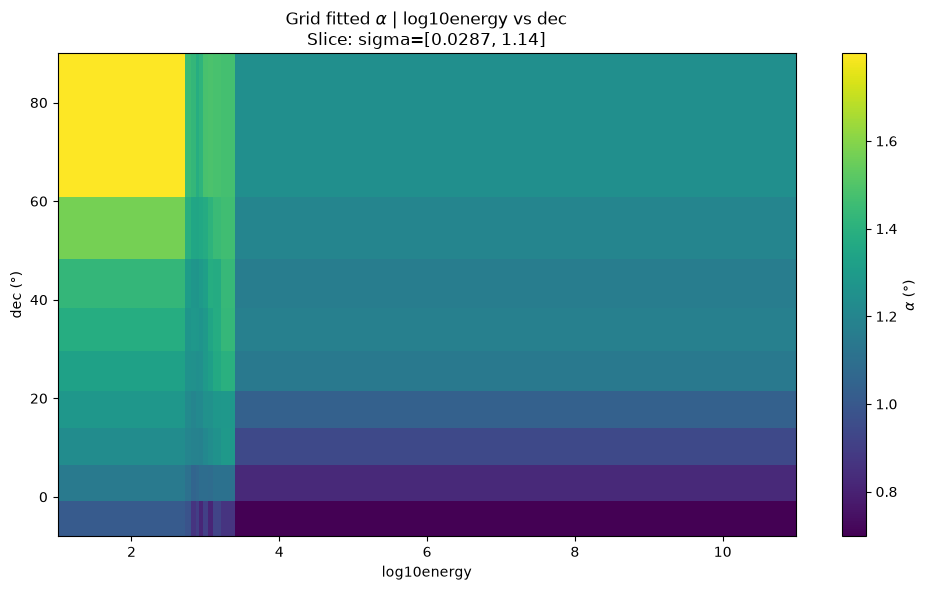

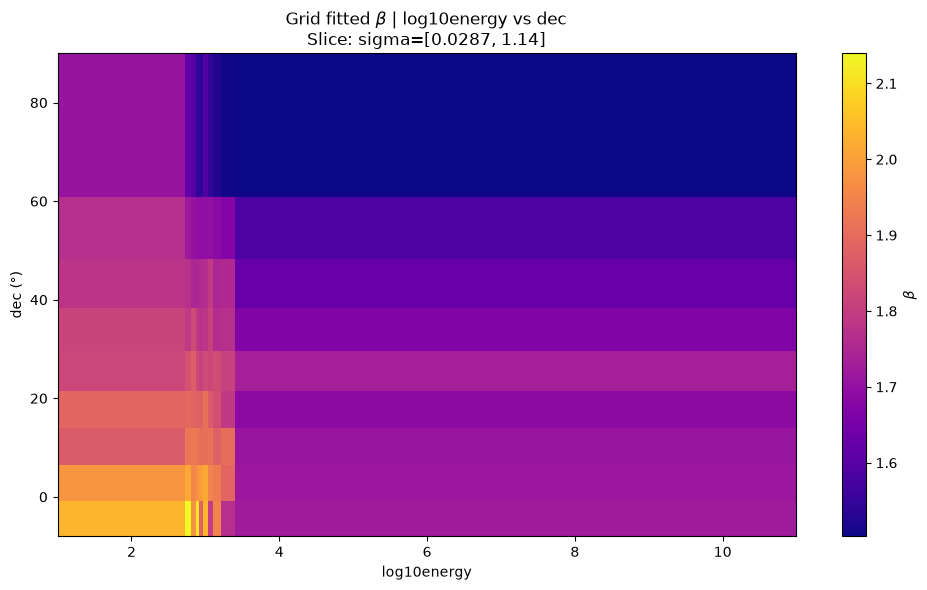

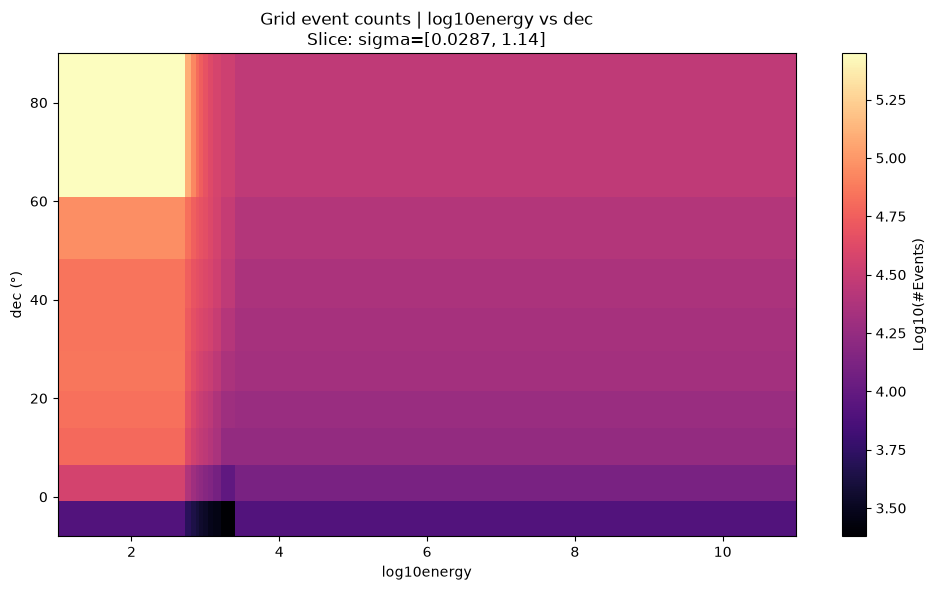

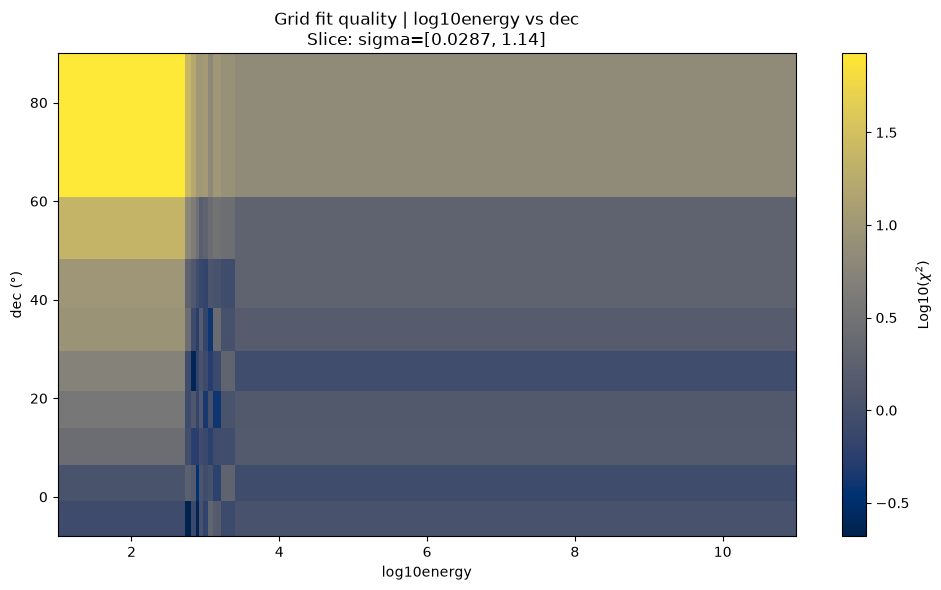

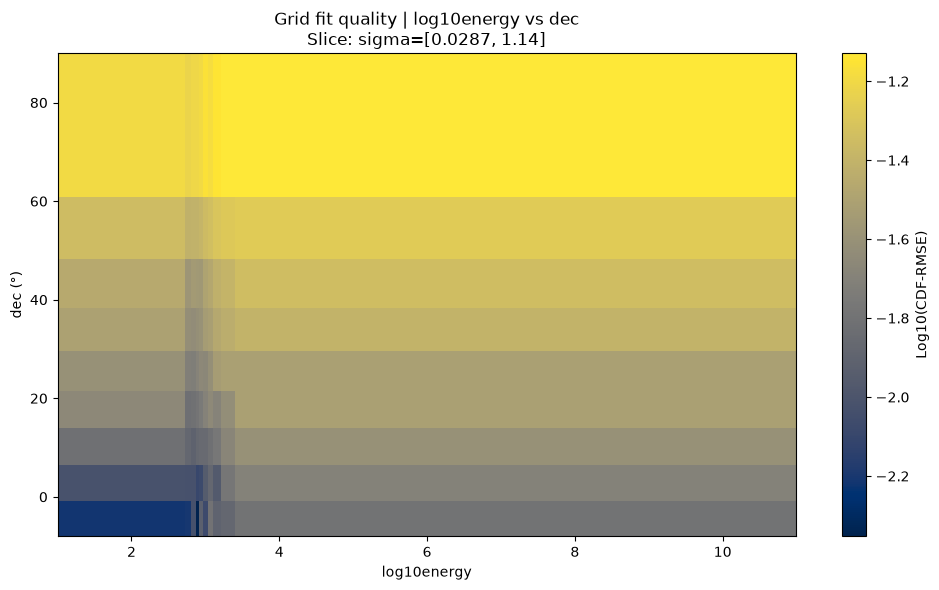

<Axes: title={'center': 'Grid fit quality | log10energy vs dec\nSlice: sigma=[0.0287, 1.14]'}, xlabel='log10energy', ylabel='dec (°)'>

In [12]:
hidden_value = np.deg2rad(0.1)
angerr_bins = fit_parameters["parametrization_bins"].item()["sigma"]

angerr_idx = np.digitize(hidden_value, angerr_bins) - 1
angerr_idx = np.clip(angerr_idx, 0, len(angerr_bins) - 2)

angerr_idx = 4

hidden_slices = {"sigma": angerr_idx}

fplt.plot_grid_fit_2d(
    fit_parameters,
    x_name="log10energy",
    y_name="dec",
    values=alpha_vals,
    title="Grid fitted $\\alpha$ | log10energy vs dec",
    cbar_label="$\\alpha$ (°)",
    cmap="viridis",
    y_to_degrees=True,
    value_to_degrees=True,
    hidden_slices=hidden_slices,
)
fplt.plot_grid_fit_2d(
    fit_parameters,
    x_name="log10energy",
    y_name="dec",
    values=beta_vals,
    title="Grid fitted $\\beta$ | log10energy vs dec",
    cbar_label="$\\beta$",
    cmap="plasma",
    y_to_degrees=True,
    hidden_slices=hidden_slices,
)
fplt.plot_grid_fit_2d(
    fit_parameters,
    x_name="log10energy",
    log_values= True,
    y_name="dec",
    values=event_counts,
    title="Grid event counts | log10energy vs dec",
    cbar_label="Log10(#Events)",
    cmap="magma",
    y_to_degrees=True,
    hidden_slices=hidden_slices,
)
fplt.plot_grid_fit_2d(
    fit_parameters,
    x_name="log10energy",
    y_name="dec",
    values=fit_quality_chi2,
    title="Grid fit quality | log10energy vs dec",
    cbar_label="Log10($\\chi^2$)",
    cmap="cividis",
    y_to_degrees=True,
    log_values=True,
    hidden_slices=hidden_slices,
)
fplt.plot_grid_fit_2d(
    fit_parameters,
    x_name="log10energy",
    y_name="dec",
    values=fit_cdf_rms,
    title="Grid fit quality | log10energy vs dec",
    cbar_label="Log10(CDF-RMSE)",
    cmap="cividis",
    y_to_degrees=True,
    log_values=True,
    hidden_slices=hidden_slices,
)

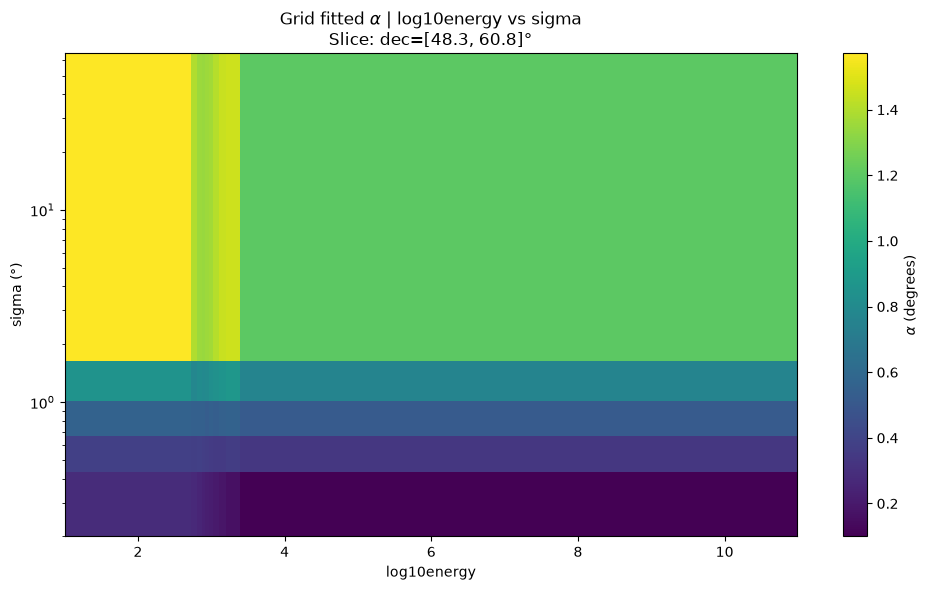

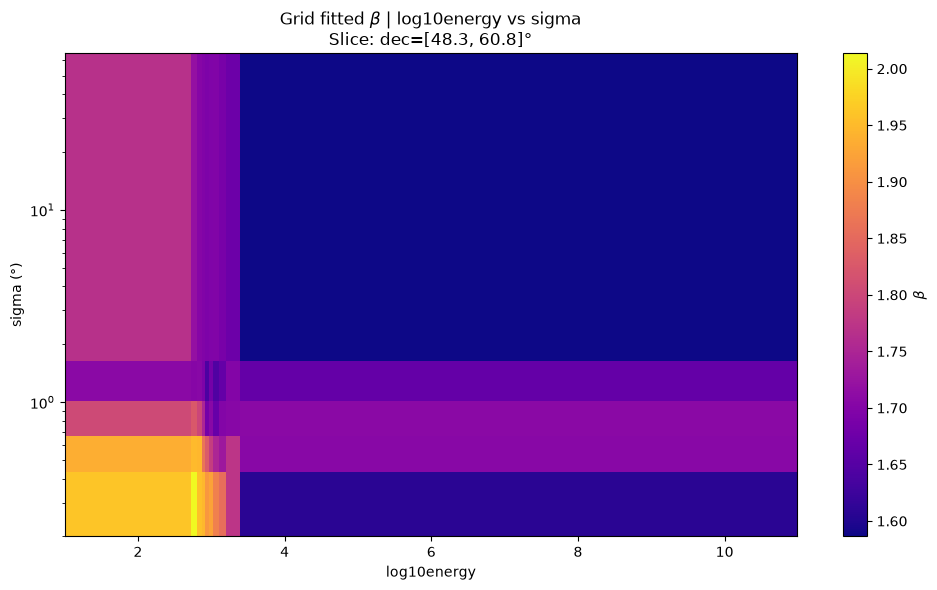

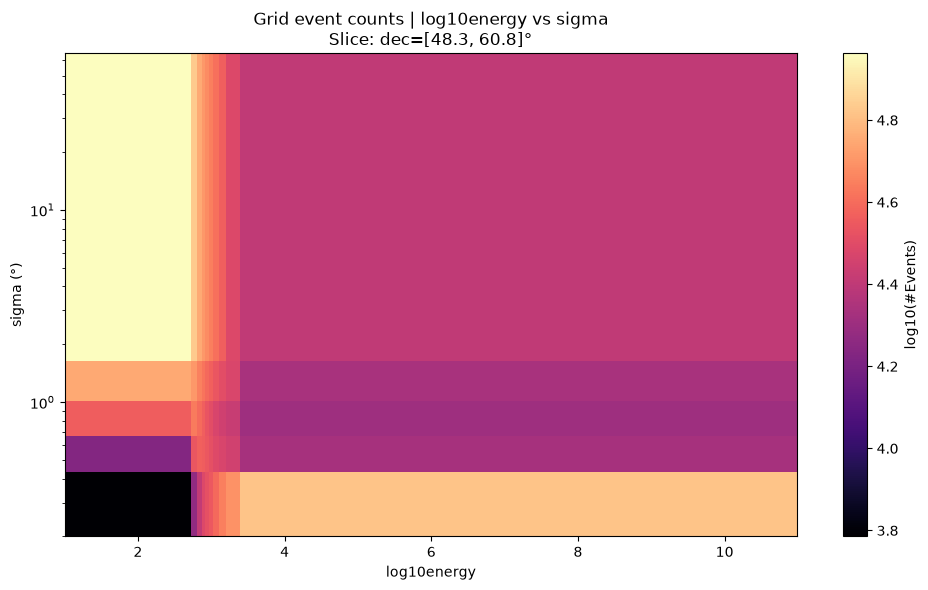

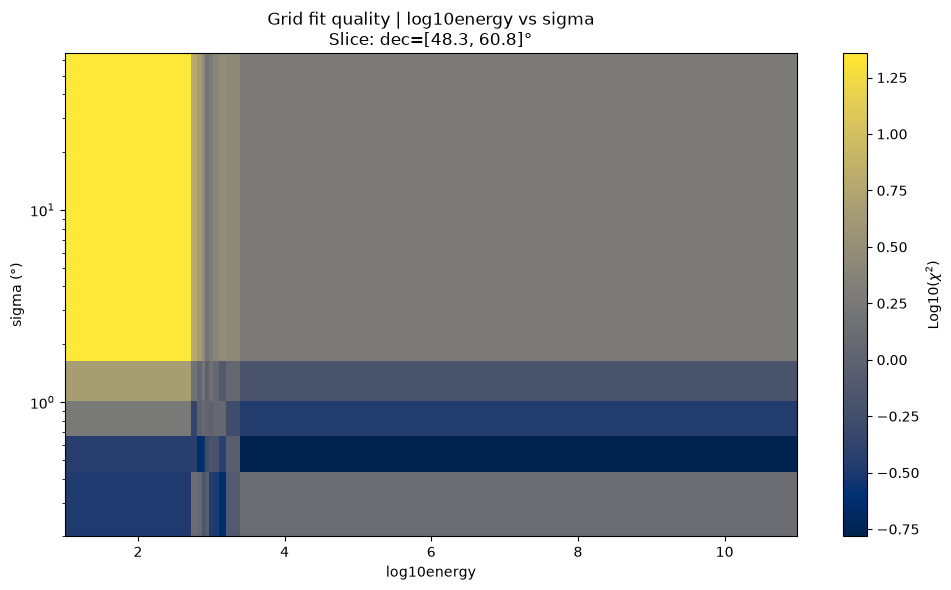

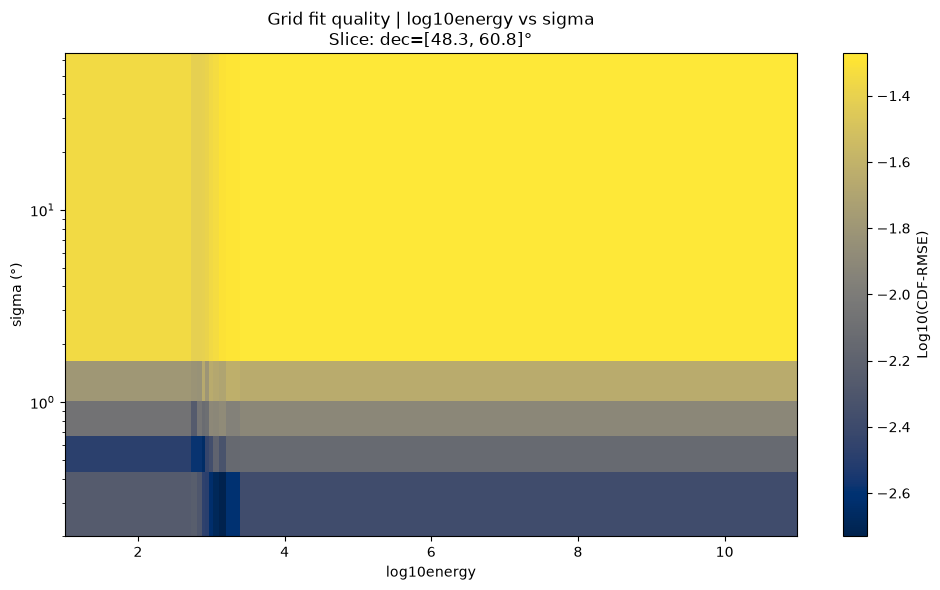

<Axes: title={'center': 'Grid fit quality | log10energy vs sigma\nSlice: dec=[48.3, 60.8]°'}, xlabel='log10energy', ylabel='sigma (°)'>

In [13]:
dec_bins = fit_parameters["parametrization_bins"].item()["dec"]
dec_idx = 7
#dec_idx = len(dec_bins) // 2 - 1

hidden_slices = {"dec": dec_idx}

fplt.plot_grid_fit_2d(
    fit_parameters,
    x_name="log10energy",
    y_name="sigma",
    values=alpha_vals,
    title="Grid fitted $\\alpha$ | log10energy vs sigma",
    cbar_label="$\\alpha$ (degrees)",
    cmap="viridis",
    y_to_degrees=True,
    value_to_degrees=True,
    log_y_scale=True,
    hidden_slices=hidden_slices,

)

fplt.plot_grid_fit_2d(
    fit_parameters,
    x_name="log10energy",
    y_name="sigma",
    values=beta_vals,
    title="Grid fitted $\\beta$ | log10energy vs sigma",
    cbar_label="$\\beta$",
    cmap="plasma",
    y_to_degrees=True,
    log_y_scale=True,
    hidden_slices=hidden_slices,
)

fplt.plot_grid_fit_2d(
    fit_parameters,
    x_name="log10energy",
    y_name="sigma",
    values=event_counts,
    title="Grid event counts | log10energy vs sigma",
    cbar_label="log10(#Events)",
    cmap="magma",
    y_to_degrees=True,
    log_values=True,
    log_y_scale=True,
    hidden_slices=hidden_slices,

)

fplt.plot_grid_fit_2d(
    fit_parameters,
    x_name="log10energy",
    y_name="sigma",
    values=fit_quality_chi2,
    title="Grid fit quality | log10energy vs sigma",
    cbar_label="Log10($\\chi^2$)",
    cmap="cividis",
    y_to_degrees=True,
    log_values=True,
    log_y_scale=True,
    hidden_slices=hidden_slices,
)

fplt.plot_grid_fit_2d(
    fit_parameters,
    x_name="log10energy",
    y_name="sigma",
    values=fit_cdf_rms,
    title="Grid fit quality | log10energy vs sigma",
    cbar_label="Log10(CDF-RMSE)",
    cmap="cividis",
    y_to_degrees=True,
    log_values=True,
    log_y_scale=True,
    hidden_slices=hidden_slices,
)

a healthy bin

Showing selected bin (0, 3, 2):
1: bin=(0, 3, 2), CDF_RMS=0.003


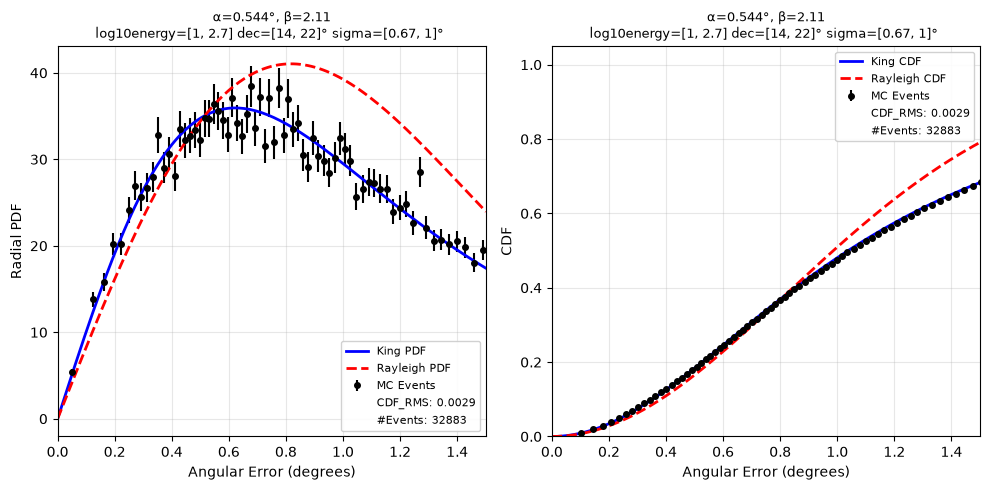

[((0, 3, 2), np.float64(0.0029480329892703555))]

In [14]:
bin_indices = [0,3, 2]
fplt.plot_selected_fit_bins(
    
    fit_parameters,
    figsize= (10, 5),
    mode="best",
    metric = 'CDF_RMS',
    x_log = False,
    y_log = False,
    normalize_fit_to_hist= False,
    plot_kind= 'radial',
    gamma_idx= gamma_idx,
    n_plots=1,
    show_data= True,
    minimum_counts=cfg['minimum_counts'],
    show_rayleigh_ref = True, 
    signal_events = ana[0].sig.as_array,
    king_pdf = king_wrapper.king_pdf,
    selected_bin_idx= bin_indices,
    curve_kind= 'both',
    x_lim = 1.5
    )

Found 450 bins with stored fits
Showing best bins:
1: bin=(6, 1, 1), CDF_RMS=0.001
2: bin=(6, 2, 0), CDF_RMS=0.001


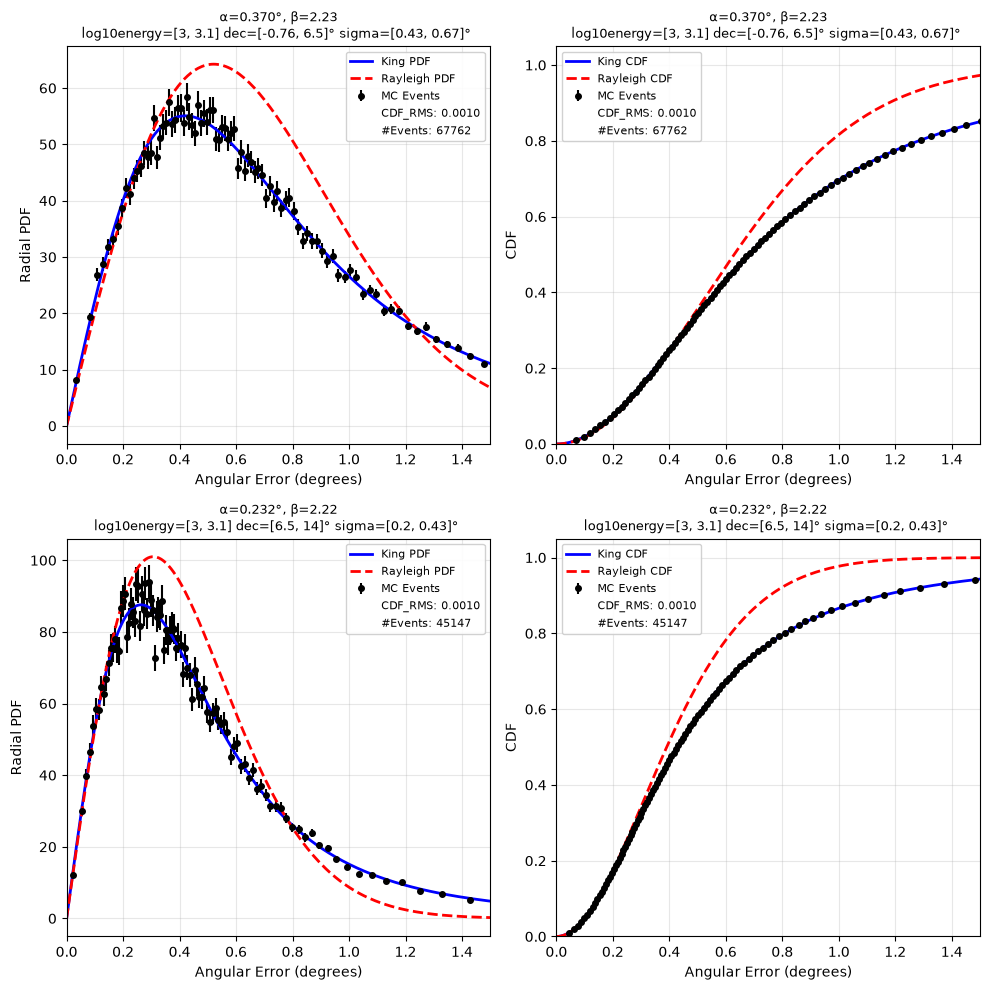

[((6, 1, 1), np.float64(0.000979931986376312)),
 ((6, 2, 0), np.float64(0.001040017177748749))]

In [15]:
fplt.plot_selected_fit_bins(
    
    fit_parameters,
    figsize= (10, 10),
    mode="best",
    metric = 'CDF_RMS',
    x_log = False,
    y_log = False,
    normalize_fit_to_hist= False,
    plot_kind= 'radial',
    gamma_idx= gamma_idx,
    n_plots= 2,
    show_data= True,
    minimum_counts=cfg['minimum_counts'],
    show_rayleigh_ref = True, 
    signal_events = ana[0].sig.as_array,
    king_pdf = king_wrapper.king_pdf,
    curve_kind= 'both',
    x_lim = 1.5
    )

some unhealthy bins:

In [16]:
bin_indices = [4,2, 9]

fplt.plot_selected_fit_bins(
    
    fit_parameters,
    figsize= (10, 5),
    mode="best",
    metric = 'CDF_chi2',
    x_log = False,
    y_log = False,
    normalize_fit_to_hist= False,
    plot_kind= 'radial',
    gamma_idx= gamma_idx,
    n_plots=1,
    show_data= True,
    minimum_counts=cfg['minimum_counts'],
    show_rayleigh_ref = True, 
    signal_events = ana[0].sig.as_array,
    king_pdf = king_wrapper.king_pdf,
    selected_bin_idx= bin_indices,
    curve_kind= 'both',
    x_lim = 10
    )
#get_bin_info(fit_parameters["parametrization_bins"], bin_indices)

/home/fkrafft/king_parametrization_binning/util/fitting_plots.py:585: SyntaxWarning: invalid escape sequence '\s'
  ax.set_title("$\sin{\delta}$" + f" = {src_sin_dec:.2f}")


ValueError: selected_bin_idx (4, 2, 9) out of range for shape (10, 9, 5).

In [ ]:
bin_indices = [0,2, 9]
fplt.plot_selected_fit_bins(
    
    fit_parameters,
    figsize= (10, 5),
    mode="best",
    metric = 'CDF_RMS',
    x_log = False,
    y_log = False,
    normalize_fit_to_hist= False,
    plot_kind= 'radial',
    gamma_idx= gamma_idx,
    n_plots=1,
    show_data= True,
    minimum_counts=cfg['minimum_counts'],
    show_rayleigh_ref = True, 
    signal_events = ana[0].sig.as_array,
    king_pdf = king_wrapper.king_pdf,
    selected_bin_idx= bin_indices,
    curve_kind= 'both',
    x_lim = 6
    )

RuntimeError: Selected bin (0, 2, 9) has only 32 events (minimum_counts=300).

Found 450 bins with stored fits
Showing worst bins:
1: bin=(9, 8, 4), CDF_RMS=0.074
2: bin=(8, 8, 4), CDF_RMS=0.074


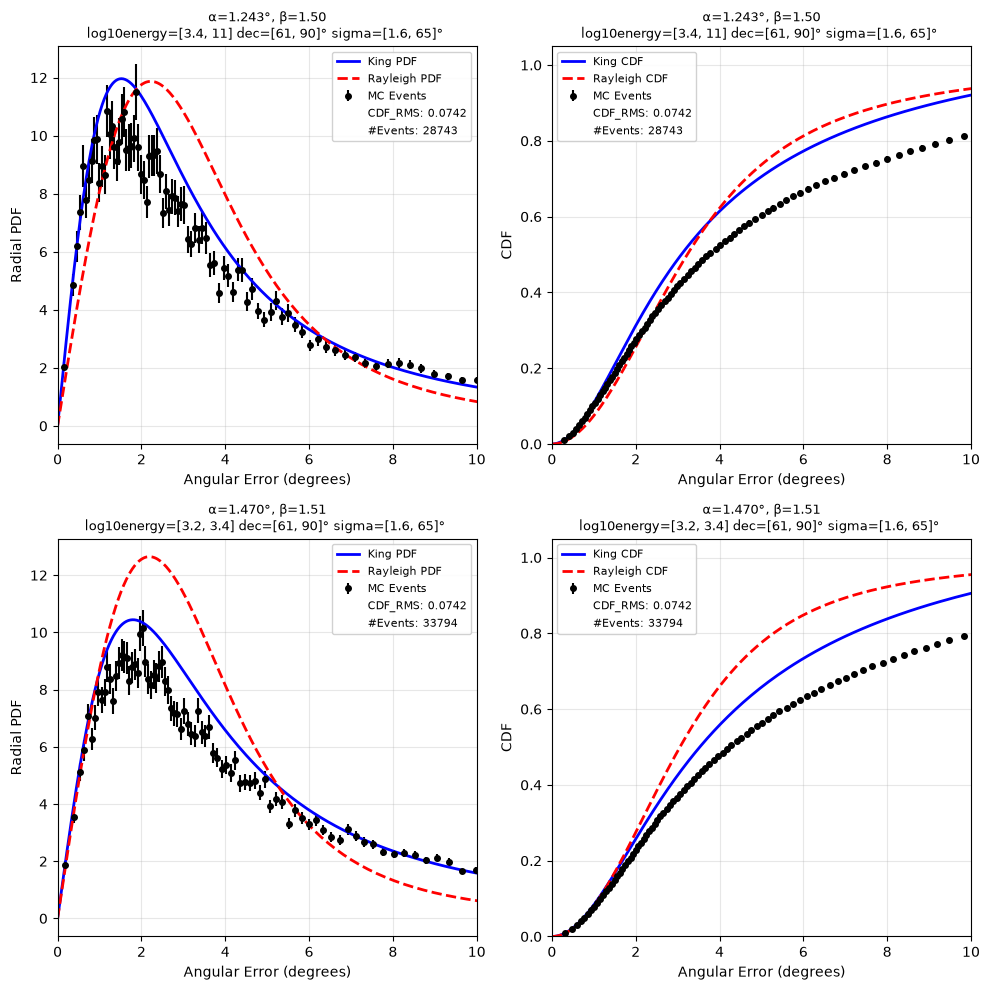

[((9, 8, 4), np.float64(0.074240237338869)),
 ((8, 8, 4), np.float64(0.0741675610034326))]

In [17]:
fplt.plot_selected_fit_bins(
    
    fit_parameters,
    figsize= (10, 10),
    mode="worst",
    metric = 'CDF_RMS',
    x_log = False,
    y_log = False,
    normalize_fit_to_hist= False,
    plot_kind= 'radial',
    gamma_idx= gamma_idx,
    n_plots=2,
    show_data= True,
    minimum_counts=cfg['minimum_counts'],
    show_rayleigh_ref = True, 
    signal_events = ana[0].sig.as_array,
    king_pdf = king_wrapper.king_pdf,
    curve_kind= 'both',
    x_lim = 10
    )

Analyze chi2 statistics of the bins:

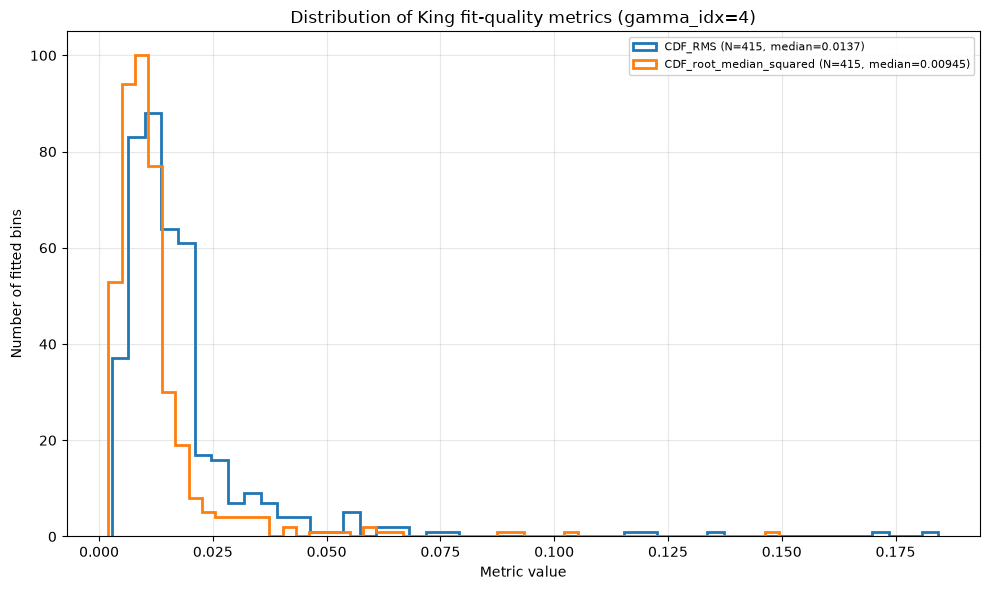

In [ ]:
metric_values = fplt.plot_fit_metric_statistics(
    fit_parameters,
    king_wrapper.king_pdf,
    density = False,
    metrics=[
        #"CDF_chi2",
        "CDF_RMS",
        "CDF_root_median_squared",
        #"CDF_density_weighted_rms",
        #'PDF_RMS', 
        #'PDF_root_median_squared'
    ],
    gamma_idx= gamma_idx,
    minimum_counts= cfg['minimum_counts'],
    bins=50,
)

## 2. Sensitivity and $3\sigma$ discovery potential flux



### Load Rayleigh benchies

In [ ]:
rayleigh_benchmark_path = Path('/data/user/fkrafft/csky_gfu_tests/2023_sig_gamma_2.5_PS_energy_bins')

In [ ]:
rayleigh_data_3sig_disc = {}
for file in rayleigh_benchmark_path.glob("rayleigh_3sig_disc*.json"):
    with open(file) as f:
        sens_data = json.load(f)

    # extract sin(dec) from filename
    # e.g. TEST_king_sens_sindec_0.2_N_1000_min_count_300_angErr12.json
    name = file.stem

    sindec_str = name.split("sindec_")[1].split("_N_")[0]
    sin_dec = float(sindec_str)

    # store inside your existing data object
    rayleigh_data_3sig_disc[sin_dec] = sens_data    
    
rayleigh_data_sens = {}
for file in rayleigh_benchmark_path.glob("rayleigh_sens*.json"):
    with open(file) as f:
        sens_data = json.load(f)

    # extract sin(dec) from filename
    # e.g. TEST_king_sens_sindec_0.2_N_1000_min_count_300_angErr12.json
    name = file.stem

    sindec_str = name.split("sindec_")[1].split("_N_")[0]
    sin_dec = float(sindec_str)

    # store inside your existing data object
    rayleigh_data_sens[sin_dec] = sens_data   

In [ ]:
#load rayleigh reference:
rayleigh_data_bias = {}
for file in rayleigh_benchmark_path.glob("rayleigh_bias_small*.json"):
    name = file.stem

    sindec_str = name.split("small_")[1].split("_N_")[0]
    sin_dec = float(sindec_str)
    with open(file, "rb") as f:
        ray_allt = pickle.load(f)
    rayleigh_data_bias[sin_dec] = ray_allt   

### Load King data

In [ ]:
king_data_3sig_disc = {
    'north' : {},
    'south' : {}
}

king_data_sens = {
    'north' : {},
    'south' : {}
}

king_data_bias = {
        'north' : {},
        'south' : {}
}
north_folder = Path(os.path.join(run_folder, 'north'))
south_folder = Path(os.path.join(run_folder, 'south'))

for run in [p for p in north_folder.iterdir() if p.is_dir()]:
    input_dir = Path(run)
    king_data_3sig_disc['north'][run.name] = {}
    king_data_sens['north'][run.name] = {}
    king_data_bias['north'][run.name] = {}
    for file in input_dir.glob("TEST_king_3sig_disc_*.json"):

        with open(file) as f:
            sens_data = json.load(f)

        # extract sin(dec) from filename
        # e.g. TEST_king_sens_sindec_0.2_N_1000_min_count_300_angErr12.json
        name = file.stem

        sindec_str = name.split("sindec_")[1].split("_N_")[0]
        sin_dec = float(sindec_str)

        # store inside your existing data object
        king_data_3sig_disc['north'][run.name][sin_dec] = sens_data 
    for file in input_dir.glob("TEST_king_sens_*.json"):

        with open(file) as f:
            sens_data = json.load(f)

        # extract sin(dec) from filename
        # e.g. TEST_king_sens_sindec_0.2_N_1000_min_count_300_angErr12.json
        name = file.stem

        sindec_str = name.split("sindec_")[1].split("_N_")[0]
        sin_dec = float(sindec_str)

        # store inside your existing data object
        king_data_sens['north'][run.name][sin_dec] = sens_data 
    for file in input_dir.glob("king_bias*.json"):

        with open(file, "rb") as f:
                allt = pickle.load(f)

        # extract sin(dec) from filename
        # e.g. TEST_king_sens_sindec_0.2_N_1000_min_count_300_angErr12.json
        name = file.stem

        sindec_str = name.split("SINDEC_")[1].split("_NTRIALS")[0]
        sin_dec = float(sindec_str)

        # store inside your existing data object
        king_data_bias['north'][run.name][sin_dec] = allt 
    #if no files: remove   
    if king_data_3sig_disc['north'][run.name] == {} or king_data_bias['north'][run.name] == {} or king_data_sens['north'][run.name] == {}:
        king_data_3sig_disc['north'].pop(run.name)
        king_data_sens['north'].pop(run.name)
        king_data_bias['north'].pop(run.name)
        
for run in [p for p in south_folder.iterdir() if p.is_dir()]:
    input_dir = Path(run)
    king_data_3sig_disc['south'][run.name] = {}
    king_data_sens['south'][run.name] = {}
    king_data_bias['south'][run.name] = {}
    for file in input_dir.glob("TEST_king_3sig_disc_*.json"):

        with open(file) as f:
            sens_data = json.load(f)

        # extract sin(dec) from filename
        # e.g. TEST_king_sens_sindec_0.2_N_1000_min_count_300_angErr12.json
        name = file.stem

        sindec_str = name.split("sindec_")[1].split("_N_")[0]
        sin_dec = float(sindec_str)

        # store inside your existing data object
        king_data_3sig_disc['south'][run.name][sin_dec] = sens_data 
    for file in input_dir.glob("TEST_king_sens_*.json"):
        try: 
            with open(file) as f:
                sens_data = json.load(f)
        except json.JSONDecodeError:
            print("BAD FILE:", file)
            print("SIZE:", file.stat().st_size)
            break
        # extract sin(dec) from filename
        # e.g. TEST_king_sens_sindec_0.2_N_1000_min_count_300_angErr12.json
        name = file.stem

        sindec_str = name.split("sindec_")[1].split("_N_")[0]
        sin_dec = float(sindec_str)

        # store inside your existing data object
        king_data_sens['south'][run.name][sin_dec] = sens_data 
    for file in input_dir.glob("king_bias*.json"):

        try:
            with open(file, "rb") as f:
                allt = pickle.load(f)
        except EOFError:
            print("BAD FILE:", file)
            print("SIZE:", file.stat().st_size)
            break

        # extract sin(dec) from filename
        # e.g. TEST_king_sens_sindec_0.2_N_1000_min_count_300_angErr12.json
        name = file.stem

        sindec_str = name.split("SINDEC_")[1].split("_NTRIALS")[0]
        sin_dec = float(sindec_str)

        # store inside your existing data object
        king_data_bias['south'][run.name][sin_dec] = allt 
    #if no files: remove   
    if king_data_3sig_disc['south'][run.name] == {} or king_data_bias['south'][run.name] == {} or king_data_sens['south'][run.name] == {}:
        king_data_3sig_disc['south'].pop(run.name)
        king_data_sens['south'].pop(run.name)
        king_data_bias['south'].pop(run.name)

### Sensitivity Flux

/home/fkrafft/king_parametrization_binning/util/plot_verification_metrics.py:250: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_diff.legend()


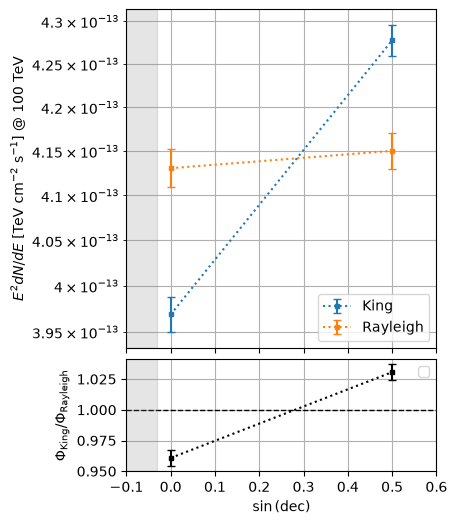

{'avg_ratio': np.float64(0.9957266929232496),
 'ratio': array([0.9608087 , 1.03064469]),
 'king_flux': array([3.96882845e-13, 4.27751799e-13]),
 'rayleigh_flux': array([4.13071662e-13, 4.15033235e-13])}

In [ ]:
plot_flux(king_data_sens,
          rayleigh_data_sens, 
          fitting_candidate,
          sky_candidate,
          x_lim = (-0.1, 0.6),
        figsize = (4, 6),
        show_title= False)

### $3\sigma$ Discovery Potential Flux

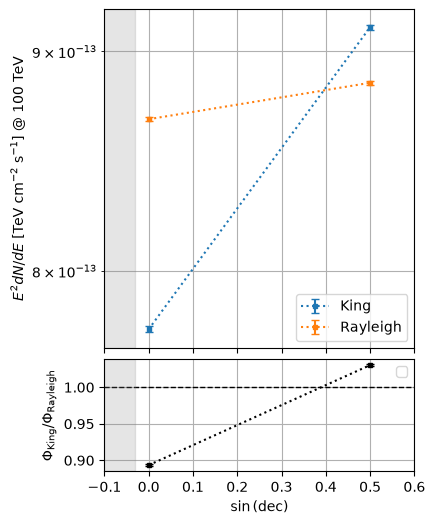

{'avg_ratio': np.float64(0.9618493756721637),
 'ratio': array([0.89342114, 1.03027761]),
 'king_flux': array([7.75374334e-13, 9.11780819e-13]),
 'rayleigh_flux': array([8.67871038e-13, 8.84985572e-13])}

In [ ]:
plot_flux(king_data_3sig_disc,
          rayleigh_data_3sig_disc, 
          fitting_candidate,
          sky_candidate,
          x_lim = (-0.1, 0.6),
          figsize = (4, 6),
          show_title= False)

## 3. Signal & Energy Bias

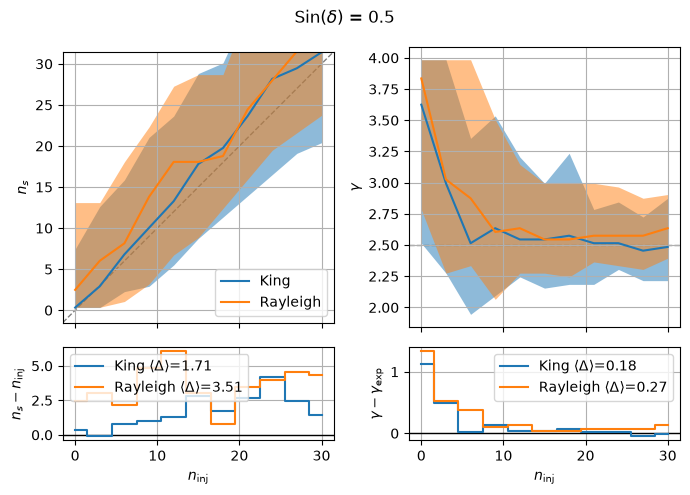

In [ ]:
n_sigs = np.r_[:31:3]
dns = np.mean(np.diff(n_sigs))
ns_bins = np.r_[n_sigs - 0.5*dns, n_sigs[-1] + 0.5*dns]

bias_summary = plot_bias(king_allt = king_data_bias[sky_candidate][fitting_candidate][fitting_candidate_sin_dec], 
          rayleigh_allt = rayleigh_data_bias[fitting_candidate_sin_dec],
          ns_bins = ns_bins, 
          expect_gamma= cfg['gamma'],
          fitting_candidate_sindec= fitting_candidate_sin_dec
          )

In [ ]:
print(bias_summary['king_mean_dev_sig']/bias_summary['rayleigh_mean_dev_sig'])
print(bias_summary['king_mean_dev_gamma']/bias_summary['rayleigh_mean_dev_gamma'])

0.4853986186933237
0.6923076923076925
